In [1]:
import os
import numpy as np
import jax.numpy as jnp
import jax
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu
from NN_class import MLP
from my_helpers import plot_u_theta, plot_kh
from functools import partial
from Pwp_class import PiecewiseLinearPolynomials
# from minmax_opt_class import pytree_l2_norm, MinMaxOptProb
from minmax_opt_class import pytree_l2_norm

from jax.example_libraries import optimizers

# import os
# os.environ['XLA_FLAGS'] = '--xla_cpu_multi_thread_eigen=true --xla_cpu_parallelism_threads=6'

In [8]:
# Optimizer Class
class MinMaxOptProb:
    def __init__(self, N_t=10, N_x=10, lr_theta=0.01, hidden_dims=(64, 64, 64), seed=0, sigma=0.1, N_perturb=5000, N_bc=100, N_ic=100,
                 t_min=0, t_max=1, x_min=0, x_max=1, k_h_rf_times=1, u0=None, u1=None, u2=None, lambda_bc_static=0.99, alpha_p_coeffs=0, 
                 f_adaptive=1000, nu=0.001, res_visc=None, res=None,):
        self.pwp = PiecewiseLinearPolynomials(N_t, N_x, t_min=t_min, t_max=t_max, x_min=x_min, x_max=x_max, times=k_h_rf_times)
        self.lr_theta = lr_theta
        self.model = MLP(hidden_dims=hidden_dims, activation=nn.tanh, lb=jnp.array([t_min, x_min]), ub=jnp.array([t_max, x_max]))
        key = jax.random.PRNGKey(seed)
        # self.params = self.model.init(key, jnp.ones((1, 2)))
        self.params = self.model.params
        # Define optimizer
        self.opt_theta = optax.adam(self.lr_theta)
        self.opt_state_theta = self.opt_theta.init(self.params)
        self.key = jax.random.PRNGKey(seed)
        self.sigma = sigma
        self.N_perturb = N_perturb
        self.N_bc = N_bc
        self.N_ic = N_ic
        # Sample points on each boundary
        self.t_bc = jnp.linspace(t_min, t_max, self.N_bc)  # t values for x=0 and x=1 boundaries
        self.x_bc = jnp.linspace(x_min, x_max, self.N_ic)  # x values for t=0 boundary
        self.u0 = u0
        self.u1 = u1
        self.u2 = u2
        self.lambda_bc_static = lambda_bc_static
        # Adaptive weights for main training
        self.lambda_ic = 1.0
        self.lambda_bc = 1.0
        self.lambda_r = 1.0
        self.f_adaptive = f_adaptive
        self.alpha = 0.9  # Moving average parameter
        self.alpha_p_coeffs = alpha_p_coeffs # Moving average parameter for k_h
        self.nu = nu
        self.res_visc = res_visc
        self.res = res
        self.gen_ibc()
        self.gen_derivative()

    def gen_ibc(self):
         # Initial condition at t_min
        self.u_t0 = self.u0(self.x_bc)
        self.tx_t0 = jnp.stack([self.pwp.t_min * jnp.ones_like(self.x_bc), self.x_bc], axis=1)

        # Left Boundary at x_min
        self.u_x0 = self.u1(self.t_bc)
        self.tx_x0 = jnp.stack([self.t_bc, self.pwp.x_min * jnp.ones_like(self.t_bc)], axis=1)

        # Right Boundary at x_max
        self.u_x1 = self.u2(self.t_bc)
        self.tx_x1 = jnp.stack([self.t_bc, self.pwp.x_max * jnp.ones_like(self.t_bc)], axis=1)
        
    def gen_derivative(self):
        # net_u = lambda params, tx: self.model.apply(params, tx).squeeze()
        net_u = lambda params, tx: self.model(params, tx).squeeze()
        self.u_eval = jit(vmap(net_u, in_axes = (None, 0)))
        self.grad_u = jit(vmap(grad(net_u, argnums=1), in_axes = (None, 0)))
        self.hessian_u = jit(vmap(hessian(net_u, argnums=1), in_axes = (None, 0)))     

    def compute_loss_opt_kh_element(self, tri_idx, p_coeffs_all, params):
        """
        Compute losses for all perturbations on a single triangle, compatible with vmap.
    
        Args:
            tri_idx: Index of the triangle.
            p_coeffs_all: Array of shape (N_perturb, 3) of perturbed coefficients.
        Returns:
            losses: Array of shape (N_perturb,) containing loss values for each perturbation.
        """
        # Retrieve precomputed quadrature points and weights
        quad_points = self.pwp.quad_points_tri[tri_idx]  # Shape: (Nq, 2)
        quad_weights = self.pwp.quad_weights_tri[tri_idx].flatten()  # Shape: (Nq,)
    
        # Evaluate the neural network and its gradients once for the triangle
        u_quad = self.u_eval(params, quad_points)
        grad_u_tx = self.grad_u(params, quad_points)
        u_t, u_x = grad_u_tx[:, 0], grad_u_tx[:, 1]
    
        # Compute residual (e.g., u_t + u * u_x), fixed for all perturbations
        residual = self.res(u_quad, u_t, u_x).flatten()  # Shape: (Nq,)
    
        # Compute k_h for all perturbations at once
        k_h_quad_all = (
            p_coeffs_all[:, 0][:, None] + 
            p_coeffs_all[:, 1][:, None] * quad_points[:, 0] + 
            p_coeffs_all[:, 2][:, None] * quad_points[:, 1]
        )  # Shape: (N_perturb, Nq)
    
        # Compute integrand for all perturbations using broadcasting
        integrand_all = residual[None, :] * jnp.sign(u_quad[None, :] - k_h_quad_all)  # Shape: (N_perturb, Nq)
    
        # Compute losses by summing over quadrature points for each perturbation
        losses = jnp.sum(quad_weights[None, :] * integrand_all, axis=1)  # Shape: (N_perturb,)
        return losses

    def maximize_kh_vec(self, params, current_key):
        Nt = self.pwp.N_elements
        vertices_all = self.pwp.triangles  # Shape: (Nt, 3, 2)
        # Evaluate model on all vertices
        u_values_all = self.u_eval(params, vertices_all.reshape(-1, 2)).reshape(Nt, 3, -1)
        
        # Compute initial coefficients
        A_all = jnp.stack([jnp.ones((Nt, 3)), vertices_all[:, :, 0], vertices_all[:, :, 1]], axis=-1)
        initial_coeffs_all = jnp.linalg.solve(A_all, u_values_all.reshape(Nt, 3, 1)).squeeze(-1)
        # print(jnp.einsum('ijk,ik->ij', A_all, initial_coeffs_all)-u_values_all)
    
        # Generate perturbations
        key, current_key = jax.random.split(current_key)
        keys = jax.random.split(key, Nt)
        perturbations_all = vmap(lambda k: self.sigma * jax.random.normal(k, (self.N_perturb, 3)))(keys)
        perturbed_coeffs_all = initial_coeffs_all[:, None, :] + perturbations_all
        # print(perturbed_coeffs_all.shape)
        # Compute losses (assuming compute_loss_tri is defined)
        losses_all = vmap(self.compute_loss_opt_kh_element, in_axes=(0, 0, None))(jnp.arange(Nt), perturbed_coeffs_all, params)
        
        # print(losses_all.shape)
        # Select best coefficients
        best_indices = jnp.argmax(losses_all, axis=1)
        best_coeffs_all = perturbed_coeffs_all[jnp.arange(Nt), best_indices]
        # print(f"The max. of optimized coef. for k_h: {jnp.max(jnp.linalg.norm(best_coeffs_all[:,1:]))}")
        return best_coeffs_all, current_key

    def compute_loss_opt_utheta_int(self, params, p_coeffs):
        # Get quadrature points and weights for this triangle
        quad_points = self.pwp.quad_points  # Shape: (Nt*Nq, 2)
        quad_weights = self.pwp.quad_weights.flatten()  # Shape: (Nt*Nq,)
    
        # Evaluate neural network and its gradients at quadrature points
        u_quad = self.u_eval(params, quad_points)
        grad_u_tx = self.grad_u(params, quad_points)
        u_t, u_x = grad_u_tx[:, 0], grad_u_tx[:, 1]
    
        # Compute the residual (example: u_t + u * u_x for a simple PDE)
        residual = self.res(u_quad, u_t, u_x).flatten()  # Shape: (Nt*Nq,)
    
        # Compute k_h at quadrature points using the element's coefficients
        p_coeffs_quad = p_coeffs[self.pwp.element_indices]  # Shape: (Nt*Nq,)
        # print(f"p_coeffs_quad shape: {p_coeffs_quad.shape}")
        k_h_quad = p_coeffs_quad[:, 0] + p_coeffs_quad[:, 1] * quad_points[:, 0] + p_coeffs_quad[:, 2] * quad_points[:, 1]  # Shape: (Nt*Nq,)

        # Define the integrand for the loss (residual * sign(u - k_h))
        integrand = residual * jnp.sign(u_quad - k_h_quad)  # Shape: (Nt*Nq,)
        interior_loss = jnp.dot(quad_weights, integrand)  # Scalar
        return interior_loss
        
    def compute_loss_opt_utheta_bc(self, params):
        return self.compute_L_ic(params) + self.compute_L_bc(params)

    def compute_loss_opt_utheta_adaptive(self, params, p_coeffs, lambda_ic, lambda_bc, lambda_r):
        """Compute total loss with adaptive weights."""
        L_ic = self.compute_L_ic(params)
        L_bc = self.compute_L_bc(params)
        L_r = self.compute_loss_opt_utheta_int(params, p_coeffs)
        total_loss = (lambda_ic * L_ic + 
                      lambda_bc * L_bc + 
                      lambda_r * L_r)
        return total_loss
        
    def compute_loss_opt_utheta(self, params, p_coeffs):
        # --- Total Loss ---
        interior_loss = self.compute_loss_opt_utheta_int(params, p_coeffs)
        boundary_loss = self.compute_loss_opt_utheta_bc(params)
        total_loss = (1-self.lambda_bc_static) * interior_loss + self.lambda_bc_static * boundary_loss
        return total_loss

    # def test_u_theta_loss(self, params):
    #     u_quad = self.u_eval(params, self.pwp.quad_points)
    #     residual = u_quad - jnp.sin(2*(2*jnp.pi*self.pwp.quad_points[:, 0] + self.pwp.quad_points[:, 1]))
    #     loss = jnp.sum(residual**2 * self.pwp.quad_weights)
    #     return loss

    def minimize_u_theta(self, params, p_coeffs, opt_state_theta):
        loss_value, grad_params = jax.value_and_grad(self.compute_loss_opt_utheta, argnums=0)(params, p_coeffs)
        # loss_value, grad_params = jax.value_and_grad(self.test_u_theta_loss)(params)
        updates, opt_state_theta = self.opt_theta.update(grad_params, opt_state_theta)
        params = optax.apply_updates(params, updates)
        return loss_value, params, opt_state_theta

    def minimize_u_theta_adaptive(self, params, p_coeffs, opt_state_theta, lambda_ic, lambda_bc, lambda_r):
        """Minimize u_theta with adaptive weights."""
        loss_value, grad_params = jax.value_and_grad(self.compute_loss_opt_utheta_adaptive, argnums=0)(params, p_coeffs, lambda_ic, 
                                                                                                       lambda_bc, lambda_r)
        updates, opt_state_theta = self.opt_theta.update(grad_params, opt_state_theta)
        params = optax.apply_updates(params, updates)
        return loss_value, params, opt_state_theta


    def pre_train_compute_loss_opt_utheta_int(self, params):
        # Get quadrature points and weights for this triangle
        quad_points = self.pwp.quad_points  # Shape: (Nt*Nq, 2)
        quad_weights = self.pwp.quad_weights.flatten()  # Shape: (Nt*Nq,)

        u_quad = self.u_eval(params, quad_points)
        grad_u_tx = self.grad_u(params, quad_points)
        u_t, u_x = grad_u_tx[:, 0], grad_u_tx[:, 1]
        hessian_u_tx = self.hessian_u(params, quad_points)
        u_xx = hessian_u_tx[:, 1, 1].flatten()  # Shape: (Nt*Nq,), second derivative w.r.t. x
        # Compute the residual (example: u_t + u * u_x for a simple PDE)
        residual = self.res_visc(u_quad, u_t, u_x, u_xx, self.nu)  # Shape: (Nt*Nq,)
        integrand = residual**2
        interior_loss = jnp.dot(quad_weights, integrand)  # Scalar
        return interior_loss

    # def pre_train_compute_loss_opt_utheta(self, params):
    #     interior_loss = self.pre_train_compute_loss_opt_utheta_int(params)
    #     boundary_loss = self.compute_loss_opt_utheta_bc(params)
    #     total_loss = (1-self.lambda_bc_static) * interior_loss + self.lambda_bc_static * boundary_loss
    #     return total_loss

    def pre_train_compute_loss_opt_utheta_adaptive(self, params, lambda_ic=0, lambda_bc=0, lambda_r=1):
        L_ic = self.compute_L_ic(params)
        L_bc = self.compute_L_bc(params)
        L_r = self.pre_train_compute_loss_opt_utheta_int(params)
        total_loss = (lambda_ic * L_ic + 
                      lambda_bc * L_bc + 
                      lambda_r * L_r)
        return total_loss, (L_r, L_ic+L_bc)

    # def pre_train_minimize_u_theta(self, params, opt_state_theta):
    #     loss_value, grad_params = jax.value_and_grad(self.pre_train_compute_loss_opt_utheta)(params)
    #     # loss_value, grad_params = jax.value_and_grad(self.test_u_theta_loss)(params)
    #     updates, opt_state_theta = self.opt_theta.update(grad_params, opt_state_theta)
    #     params = optax.apply_updates(params, updates)
    #     return loss_value, params, opt_state_theta

    def pre_train_minimize_u_theta_adaptive(self, params, opt_state_theta, lambda_ic=0, lambda_bc=0, lambda_r=1):
        (_, L_all), grad_params = jax.value_and_grad(self.pre_train_compute_loss_opt_utheta_adaptive, 
                                                     argnums=0, has_aux=True)(params, lambda_ic, lambda_bc, lambda_r)
        # loss_val, grad_params = jax.value_and_grad(self.test_u_theta_loss)(params)
        updates, opt_state_theta = self.opt_theta.update(grad_params, opt_state_theta)
        params = optax.apply_updates(params, updates)
        return L_all, params, opt_state_theta

    def pre_train_step(self, iter):
        if iter % self.f_adaptive == 0:
            self.update_adaptive_weights(self.params, self.pwp.coeffs, phase='pre-train')
            print(f"Iteration {iter}, lambda_ic: {self.lambda_ic}, lambda_bc: {self.lambda_bc}, lambda_r: {self.lambda_r}.")
        (loss_int, loss_ibc), self.params, self.opt_state_theta = self.minimize_u(self.params, self.opt_state_theta,
                                                                         self.lambda_ic, self.lambda_bc, self.lambda_r)
        # return self.compute_loss_opt_utheta(self.params)
        return loss_int, loss_ibc
        # return self.pre_train_compute_loss_opt_utheta_int(self.params), self.compute_loss_opt_utheta_bc(self.params)
        
    def pre_train_process(self, pre_train_num_iterations, save_loss=True, save_model=True):
        print("\nStarting Pre-Train Stage")
        start_time = time.perf_counter()
        self.lambda_ic = 1.0
        self.lambda_bc = 1.0
        self.lambda_r = 1.0
        self.pre_loss_int_history = []
        self.pre_loss_bc_history = []
        self.minimize_u = jit(self.pre_train_minimize_u_theta_adaptive)
        # self.minimize_u = self.pre_train_minimize_u_theta
        for iter in range(pre_train_num_iterations):
            loss_int, loss_ibc = self.pre_train_step(iter)
            self.pre_loss_int_history.append(loss_int)
            self.pre_loss_bc_history.append(loss_ibc)
            if iter % 200 == 0:
                print(f"Pre-train Iteration {iter}, Loss_int: {loss_int:.8f}, Loss_ibc: {loss_ibc:.8f}")
        end_time = time.perf_counter()
        pre_train_total_time = end_time - start_time
        print(f"Pre-train total time: {pre_train_total_time:.8f} seconds")
        print(f"Pre-train average time per iteration: {pre_train_total_time / pre_train_num_iterations:.9e} seconds")
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        if save_loss:
            # Save training loss histories with consistent naming
            loss_int_path = os.path.join('..', 'data', f'pre_train_loss_int_history_{timestamp}.pkl')
            with open(loss_int_path, 'wb') as f:
                pickle.dump(self.pre_loss_int_history, f)
            loss_bc_path = os.path.join('..', 'data', f'pre_train_loss_bc_history_{timestamp}.pkl')
            with open(loss_bc_path, 'wb') as f:
                pickle.dump(self.pre_loss_bc_history, f)
            print(f"Pre-train loss histories saved to {loss_int_path} and {loss_bc_path}")
        
        if save_model:
            # Save both params and architecture info
            model_path = os.path.join('..', 'data', f'pre_train_model_{timestamp}.pkl')
            self.save_model(model_path)
            print(f"Pre-train model saved to {model_path}")
                

    # --- Define Individual Loss Components ---
    def compute_L_ic(self, params):
        """Compute initial condition loss L_ic."""
        # Intial condition at t_min
        return jnp.mean((self.u_eval(params, self.tx_t0) - self.u_t0)**2)

    def compute_L_bc(self, params):
        """Compute boundary condition loss L_bc."""
        # Left Boundary at x_min
        u_x0_nn = self.u_eval(params, self.tx_x0)
        bc_x0_loss = jnp.mean((u_x0_nn - self.u_x0)**2)
        # Right Boundary at x_max
        u_x1_nn = self.u_eval(params, self.tx_x1)
        bc_x1_loss = jnp.mean((u_x1_nn - self.u_x1)**2)
        return bc_x0_loss + bc_x1_loss

    # --- Adaptive Weight Update ---
    def update_adaptive_weights(self, params, p_coeffs, phase='pre-train'):
        """Update lambda_ic, lambda_bc, and lambda_r every 10 iterations."""
        # Compute gradients
        grad_L_ic = grad(self.compute_L_ic)(params)
        grad_L_bc = grad(self.compute_L_bc)(params)
        if phase=='pre-train':
            grad_L_int = grad(lambda p: self.pre_train_compute_loss_opt_utheta_int(p))(params)
        elif phase=='train':
            grad_L_int = grad(lambda p: self.compute_loss_opt_utheta_int(p, p_coeffs))(params)

        # Compute L2 norms
        norm_ic = pytree_l2_norm(grad_L_ic)
        norm_bc = pytree_l2_norm(grad_L_bc)
        norm_r = pytree_l2_norm(grad_L_int)

        # Sum of norms with epsilon to avoid division by zero
        epsilon = 1e-7
        sum_norm = norm_ic + norm_bc + norm_r + 3*epsilon

        # Compute hat_lambda values
        hat_lambda_ic = jnp.clip(sum_norm / (norm_ic + epsilon), a_min=1, a_max=1e7)
        hat_lambda_bc = jnp.clip(sum_norm / (norm_bc + epsilon), a_min=1, a_max=1e7)
        hat_lambda_r = jnp.clip(sum_norm / (norm_r + epsilon), a_min=1, a_max=1e7)

        # Update weights using moving average
        self.lambda_ic = self.alpha * self.lambda_ic + (1 - self.alpha) * hat_lambda_ic
        self.lambda_bc = self.alpha * self.lambda_bc + (1 - self.alpha) * hat_lambda_bc
        self.lambda_r = self.alpha * self.lambda_r + (1 - self.alpha) * hat_lambda_r
    


    def train_step(self, iter, moving_avg=True):
        if iter % self.f_adaptive == 0:
            self.update_adaptive_weights(self.params, self.pwp.coeffs, phase='train')
            print(f"Iteration {iter}, lambda_ic: {self.lambda_ic:.8f}, lambda_bc: {self.lambda_bc:.8f}, lambda_r: {self.lambda_r:.8f}.")
        # First, we minimize u_theta since k_h has been maximized when loading the model.
        # minimize_u_theta = jit(self.minimize_u_theta)
        # minimize_u_theta = self.minimize_u_theta
        # loss_value, self.params, self.opt_state_theta = minimize_u_theta(self.params, self.pwp.coeffs, self.opt_state_theta)
        minimize_u_theta = jit(self.minimize_u_theta_adaptive)
        loss_value, self.params, self.opt_state_theta = minimize_u_theta(self.params, self.pwp.coeffs, self.opt_state_theta, 
                                                                         self.lambda_ic, self.lambda_bc, self.lambda_r)
        
        if iter % 1 == 0:
            print(f"Iteration {iter}, before maximize k_h, loss: {self.compute_loss_opt_utheta_int(self.params, self.pwp.coeffs):.8f}, {self.compute_loss_opt_utheta_bc(self.params):.8f}.")
        hat_coeffs, self.key = self.maximize_kh(self.params, self.key)
        # Moving average for self.pwp.coeffs
        self.pwp.coeffs = self.alpha_p_coeffs * self.pwp.coeffs + (1 - self.alpha_p_coeffs) * hat_coeffs
        if iter % 1 == 0:
            print(f"Iteration {iter}, after maximize k_h, loss: {self.compute_loss_opt_utheta_int(self.params, self.pwp.coeffs):.8f}, {self.compute_loss_opt_utheta_bc(self.params):.8f}.")
        # return self.compute_loss_opt_utheta(self.params)
        return self.compute_loss_opt_utheta_int(self.params, self.pwp.coeffs), self.compute_loss_opt_utheta_bc(self.params)

    def train_process(self, train_num_iterations, save_loss=True, save_model=True):
        print("\nStarting Train Stage")
        start_time = time.perf_counter()
        self.lambda_ic = 1.0
        self.lambda_bc = 1.0
        self.lambda_r = 1.0
        self.loss_int_history = []
        self.loss_bc_history = []
        # Then we maximize k_h
        self.maximize_kh = jit(self.maximize_kh_vec)
        # self.maximize_kh = self.maximize_kh_vec
        for iter in range(train_num_iterations):
            loss_int, loss_bc = self.train_step(iter)
            self.loss_int_history.append(loss_int)
            self.loss_bc_history.append(loss_bc)
            if iter % 10 == 0:
                print(f"Train Iteration {iter}, Loss_int: {loss_int:.8f}, Loss_bc: {loss_bc:.8f}")
        end_time = time.perf_counter()
        train_total_time = (end_time - start_time)
        print(f"Train total time: {train_total_time:.8f} seconds")
        print(f"Train average time per iteration: {train_total_time / train_num_iterations:.9e} seconds")
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        if save_loss:
            # Save training loss histories with consistent naming
            loss_int_path = os.path.join('..', 'data', f'loss_int_history_{timestamp}.pkl')
            with open(loss_int_path, 'wb') as f:
                pickle.dump(self.loss_int_history, f)
            loss_bc_path = os.path.join('..', 'data', f'loss_bc_history_{timestamp}.pkl')
            with open(loss_bc_path, 'wb') as f:
                pickle.dump(self.loss_bc_history, f)
            print(f"Loss histories saved to {loss_int_path} and {loss_bc_path}")
        
        if save_model:
            # Save both params and architecture info
            model_path = os.path.join('..', 'data', f'train_model_{timestamp}.pkl')
            self.save_model(model_path)
            print(f"Train model saved to {model_path}")

    def save_model(self, model_path):
        save_dict = {
            'params': self.params,
            'hidden_dims': self.model.hidden_dims
        }
        with open(model_path, 'wb') as f:
            pickle.dump(save_dict, f)

    def load_model(self, model_path):
        """
        Load the saved model parameters and recreate the architecture.

        Args:
            model_path: Path to the saved model file (e.g., '../data/train_model_20231015_123456.pkl').

        Returns:
            None (updates self.params and self.model)
        """
        with open(model_path, 'rb') as f:
            loaded_data = pickle.load(f)

        # Extract parameters and architecture info
        loaded_params = loaded_data['params']
        loaded_hidden_dims = loaded_data['hidden_dims']

        # Recreate the model with the same architecture
        self.model = MLP(hidden_dims=loaded_hidden_dims)
        
        # Initialize with a dummy key to set up the structure (params will be overwritten)
        key = jax.random.PRNGKey(0)  # Any seed; params will be replaced
        dummy_input = jnp.ones((1, 2))
        self.params = self.model.init(key, dummy_input)

        # Assign the loaded parameters
        self.params = loaded_params

        # Re-initialize optimizer state with loaded params
        self.opt_theta = optax.adam(self.lr_theta)
        self.opt_state_theta = self.opt_theta.init(self.params)
        print(f"Model loaded from {model_path} with hidden_dims: {loaded_hidden_dims}")
        self.pwp.coeffs, self.key = self.maximize_kh_vec(self.params, self.key)
        loss_int, loss_bc = self.compute_loss_opt_utheta_int(self.params, self.pwp.coeffs), self.compute_loss_opt_utheta_bc(self.params)
        print(f"For the loaded model, Loss_int: {loss_int:.8f}, Loss_bc: {loss_bc:.8f}.")


In [9]:
eps0 = 1e-4
def smooth_sign(x, eps = eps0):
    return 2*jax.nn.sigmoid(x/eps)-1

# def u0(x):
#     return 0.5 * (smooth_sign(x - 0.4) - smooth_sign(x - 0.6))

# def u1(x):
#     return 0

# def u2(x):
#     return 0


# Define boundary and initial conditions
import jax.numpy as jnp

def u_exact(t, x):
    # Initialize u as zero
    u = 0.0
    
    # Condition 1: x < 0, u = 0 (already zero by default)
    # Condition 2: 0 < x < t and t > 0, u = x/t
    u = jnp.where((x > 0) & (x < t) & (t > 0), x / t, u)
    
    # Condition 3: t < x < 1 + t/2, u = 1
    u = jnp.where((x > t) & (x < 1 + t / 2), 1.0, u)
    
    # Condition 4: x > 1 + t/2, u = 0 (already zero by default)
    return u
vmap_u_exact = vmap(u_exact, in_axes=(0, 0), out_axes=0)

def u0(x):
    u = jnp.zeros_like(x)
    u = jnp.where((x > 0) & (x < 1), 1.0, u)
    return u

# Boundary at x=-1
def u1(x):
    return 0

# Boundary at x=1
def u2(x):
    return 0


def res_visc(u_quad, u_t, u_x, u_xx, nu, u_exact=0):
    # print(f"u_quad shape: {u_quad.shape}")
    # print(f"u2_x shape: {u2_x.shape}")
    # print(f"u_xx shape: {u_xx.shape}")
    return u_t + u_quad*u_x - nu*u_xx
    # return u_t + 0.8*u_x - nu*u_xx
    # return jnp.zeros_like(u_quad)
    # return u_quad - u_exact

def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x
    # return u_t + 0.8*u_x

# Initialize separate loss history lists for each stage
pre_loss_int_history = []
pre_loss_bc_history = []
train_loss_int_history = []
train_loss_bc_history = []

# Function to plot loss history
def plot_loss_history(loss_int, loss_bc, title):
    plt.figure()
    plt.plot(loss_int, label='Loss Interior')
    plt.plot(loss_bc, label='Loss Boundary')
    plt.xlabel('Iteration')
    plt.ylabel('Loss (log scale)')
    plt.yscale('log')
    plt.grid(True, which="both", ls="--")
    plt.legend()
    plt.title(title)
    plt.show()


In [10]:
u0(np.ones(10)-0.1)

Array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.], dtype=float32)

In [11]:
# Initialize the optimization problem
optProb = MinMaxOptProb(
    N_t=16,
    N_x=32,
    lr_theta=0.0002,
    N_bc=100,
    N_ic=400,
    t_min=0, t_max=1, x_min=-1, x_max=1,
    hidden_dims=(64, 64, 64, 64),
    seed=0,
    u0=u0, u1=u1, u2=u2,
    nu=0.01/jnp.pi,
    res_visc=res_visc,
    res=res,
)

# Pre-train stage
pre_train_num_iterations = 5000
optProb.load_model('../data/pre_train_model_20250410_220147.pkl')
# plot_u_theta(optProb.model, optProb.params, M_t=50, M_x=200, t_min=0.0, t_max=1, x_min=-1.0, x_max=1.0)  # Plot initial model state
# optProb.pre_train_process(pre_train_num_iterations)
plot_u_theta(optProb.model, optProb.params, M_t=50, M_x=200, t_min=0.0, t_max=1, x_min=-1.0, x_max=1.0)  # Plot after pre-train

# Plot pre-train loss history
plot_loss_history(optProb.pre_loss_int_history, optProb.pre_loss_bc_history, 'Pre-train Loss History')


ValueError: Bounds lb and ub must be provided for normalization.

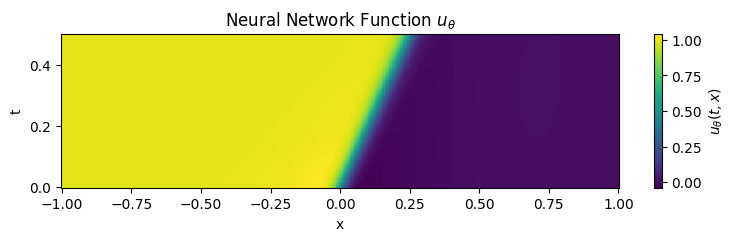

In [51]:
# optProb.sigma = 0.1
# optProb.N_perturb = 5000
# optProb.load_model('../data/pre_train_model_20250410_220147.pkl')
plot_u_theta(optProb.model, optProb.params, M_t=100, M_x=400, t_min=0.0, t_max=0.5, x_min=-1.0, x_max=1.0)  # Plot after pre-train
# plot_kh(optProb.pwp)

In [70]:
%timeit optProb.u_eval(optProb.params, quad_points)

2.21 ms ± 43.2 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [72]:
optProb = MinMaxOptProb(
    N_t=32,
    N_x=32,
    lr_theta=0.001,
    hidden_dims=(64, 64, 64, 64),
    seed=0,
    u0=u0, u1=u1, u2=u2,
)
optProb.load_model('../data/pre_train_model_20250402_162344.pkl')

# Train stage
train_num_iterations = 2000

plot_u_theta(optProb.model, optProb.params, M_t=100, M_x=100)  # Plot before train
optProb.train_process(train_num_iterations)
plot_u_theta(optProb.model, optProb.params, M_t=100, M_x=100)  # Plot after train

# Plot train loss history
plot_loss_history(optProb.loss_int_history, optProb.loss_bc_history, 'Train Loss History')

Model loaded from ../data/pre_train_model_20250402_162344.pkl with hidden_dims: (64, 64, 64, 64)


ScopeParamNotFoundError: Could not find parameter named "kernel" in scope "/layers_0". (https://flax.readthedocs.io/en/latest/api_reference/flax.errors.html#flax.errors.ScopeParamNotFoundError)

In [4]:
# This is a training without pre-training!
optProb = MinMaxOptProb(
    N_t=32,
    N_x=96,
    lr_theta=0.0002,
    N_bc=100,
    N_ic=400,
    t_min=0, t_max=1, x_min=-0.25, x_max=2.75,
    hidden_dims=(64, 64, 64, 64),
    seed=0,
    u0=u0, u1=u1, u2=u2,
    nu=0.0,
    res_visc=res_visc,
    res=res,
)


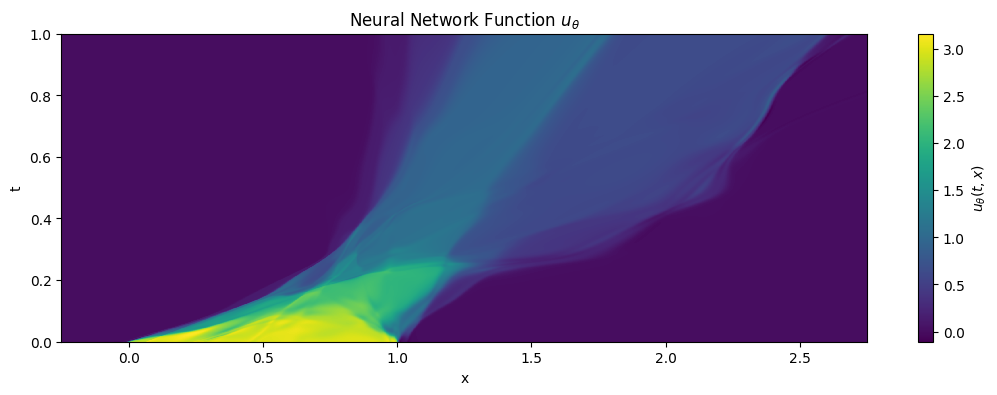


Starting Train Stage
Iteration 0, lambda_ic: 98.86070251, lambda_bc: 51012.53906250, lambda_r: 1.00114167.
Iteration 0, before maximize k_h, loss: 2.89568281, 0.00516207.
Iteration 0, after maximize k_h, loss: 3.03074050, 0.00516207.
Train Iteration 0, Loss_int: 3.03074050, Loss_bc: 0.00516207
Iteration 1, before maximize k_h, loss: 2.93218589, 0.00515700.
Iteration 1, after maximize k_h, loss: 3.02478838, 0.00515700.
Iteration 2, before maximize k_h, loss: 2.79187799, 0.00516221.
Iteration 2, after maximize k_h, loss: 3.03186178, 0.00516221.
Iteration 3, before maximize k_h, loss: 2.69287086, 0.00516811.
Iteration 3, after maximize k_h, loss: 3.03899264, 0.00516811.
Iteration 4, before maximize k_h, loss: 2.90285325, 0.00518027.
Iteration 4, after maximize k_h, loss: 3.05537987, 0.00518027.
Iteration 5, before maximize k_h, loss: 2.90491295, 0.00518831.
Iteration 5, after maximize k_h, loss: 3.01752806, 0.00518831.
Iteration 6, before maximize k_h, loss: 2.79873347, 0.00523720.
Itera

KeyboardInterrupt: 

In [6]:
optProb.load_model('../data/pre_train_model_20250402_162344.pkl')
# Train stage
train_num_iterations = 5000

plot_u_theta(optProb.model, optProb.params, M_t=1000, M_x=2000, t_min=0.0, t_max=1.0, x_min=-0.25, x_max=2.75)  # Plot initial model state
optProb.train_process(train_num_iterations)
plot_u_theta(optProb.model, optProb.params, M_t=1000, M_x=2000, t_min=0.0, t_max=1.0, x_min=-0.25, x_max=2.75)  # Plot initial model state

# Plot train loss history
plot_loss_history(optProb.loss_int_history, optProb.loss_bc_history, 'Train Loss History')

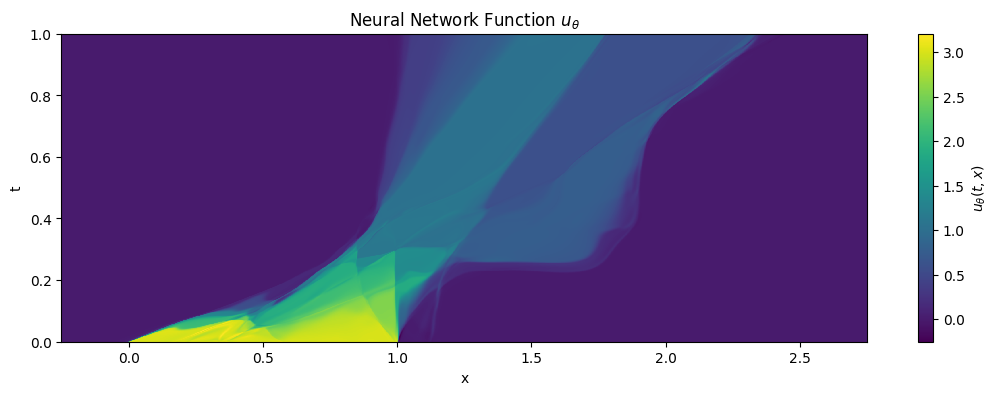

In [7]:
plot_u_theta(optProb.model, optProb.params, M_t=1000, M_x=2000, t_min=0.0, t_max=1.0, x_min=-0.25, x_max=2.75)

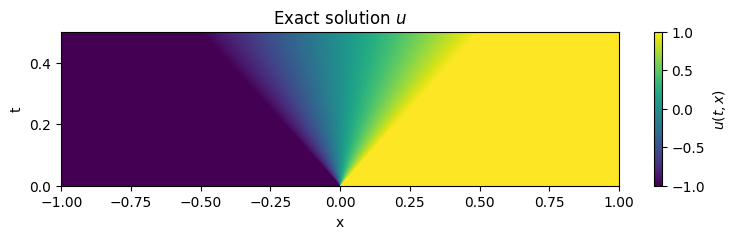

In [13]:
import matplotlib.pyplot as plt
import jax.numpy as jnp

def plot_u(M_t=100, M_x=100, t_min=0.0, t_max=0.5, x_min=0.0, x_max=1.0):

    # Create a grid for t and x over the specified ranges
    t_grid = jnp.linspace(t_min, t_max, M_t)
    x_grid = jnp.linspace(x_min, x_max, M_x)
    t, x = jnp.meshgrid(t_grid, x_grid, indexing='ij')  # Shapes: (M_t, M_x)

    # Flatten the grid for batch evaluation
    tx_points = jnp.stack([t.ravel(), x.ravel()], axis=1)  # Shape: (M_t * M_x, 2)

    # Compute u(t, x) using piecewise conditions
    t_vals = tx_points[:, 0]
    x_vals = tx_points[:, 1]
    condition1 = x_vals <= -t_vals
    condition2 = (x_vals > -t_vals) & (x_vals <= t_vals)
    condition3 = x_vals > t_vals
    u_values = jnp.where(condition1, -1.0,
                         jnp.where(condition2, x_vals / t_vals, 1.0))

    # Reshape u_values to match the grid shape
    u_values = u_values.reshape(M_t, M_x)  # Shape: (M_t, M_x)

    # Create the plot with adjusted figure size
    height = int((t_max - t_min) * 4)
    width = int((x_max - x_min) * 4 + 1)
    plt.figure(figsize=(width, height))
    plt.pcolormesh(x_grid, t_grid, u_values, shading='nearest', cmap='viridis')
    plt.colorbar(label='$u(t, x)$')
    plt.xlabel('x')
    plt.ylabel('t')
    plt.title('Exact solution $u$')
    plt.show()

# Optional: Example usage
if __name__ == "__main__":
    # Example with a domain that shows all regions, e.g., x in [-1, 1], t in [0, 1]
    plot_u(M_t=1000, M_x=2000, t_min=0.0, t_max=0.5, x_min=-1.0, x_max=1.0)

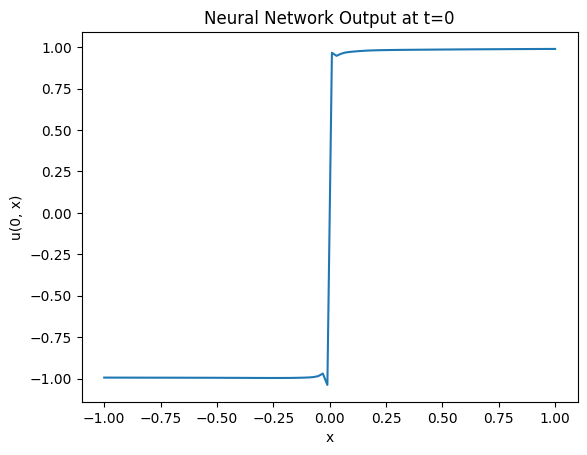

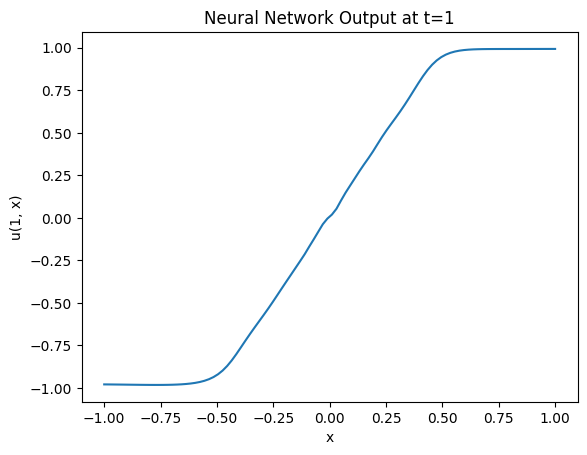

In [14]:
import jax.numpy as jnp
import matplotlib.pyplot as plt

def plot_at_t1(predict_fn, x_range=(0, 1), num_points=100, filename='plot.eps'):
    """
    Plot the neural network output at t=1 over a range of x values and save as .eps.

    Args:
        predict_fn: A callable that takes a batch of [t, x] inputs and returns outputs.
                    Example: lambda inputs: model.apply({'params': params}, inputs)
        x_range: Tuple (x_min, x_max) specifying the range of x values. Default is (0, 1).
        num_points: Number of points to evaluate and plot. Default is 100.
        filename: Name of the file to save the plot, including '.eps' extension. Default is 'plot.eps'.
    """
    # Generate x values over the specified range
    x = jnp.linspace(x_range[0], x_range[1], num_points)
    
    # Create inputs with t=1 and varying x
    t0 = jnp.zeros_like(x) * 1.0
    inputs0 = jnp.stack([t0, x], axis=1)  # Shape: (num_points, 2)
    t1 = jnp.ones_like(x) * 0.5
    inputs1 = jnp.stack([t1, x], axis=1)  # Shape: (num_points, 2)
    
    # Evaluate the neural network on the inputs
    outputs0 = predict_fn(inputs0)  # Shape: (num_points,)
    outputs1 = predict_fn(inputs1)  # Shape: (num_points,)
    
    # Create the plot
    plt.figure()
    plt.plot(x, outputs0)
    plt.xlabel('x')
    plt.ylabel('u(0, x)')
    plt.title('Neural Network Output at t=0')

    plt.figure()
    plt.plot(x, outputs1)
    plt.xlabel('x')
    plt.ylabel('u(1, x)')
    plt.title('Neural Network Output at t=1')
    
    # Save the plot in .eps format
    # plt.savefig(filename, format='eps')
    # plt.close()  # Close the figure to free memory
# Assuming 'model' and 'params' are defined (e.g., from a Flax neural network)
predict_fn = lambda inputs: optProb.model.apply({'params': optProb.params}, inputs)

# Call the plotting function
plot_at_t1(predict_fn, x_range=(-1, 1), filename='output_at_t1.eps')

In [ ]:
import matplotlib.pyplot as plt

def u0(x):
    # return 2*smooth_sign(x) - 1
    return -0.5*(jnp.sign(x) - 1)
xx = np.linspace(-1,1,100)
yy = u0(xx)

plt.plot(xx, yy)

In [27]:
import matplotlib.pyplot as plt
import jax.numpy as jnp



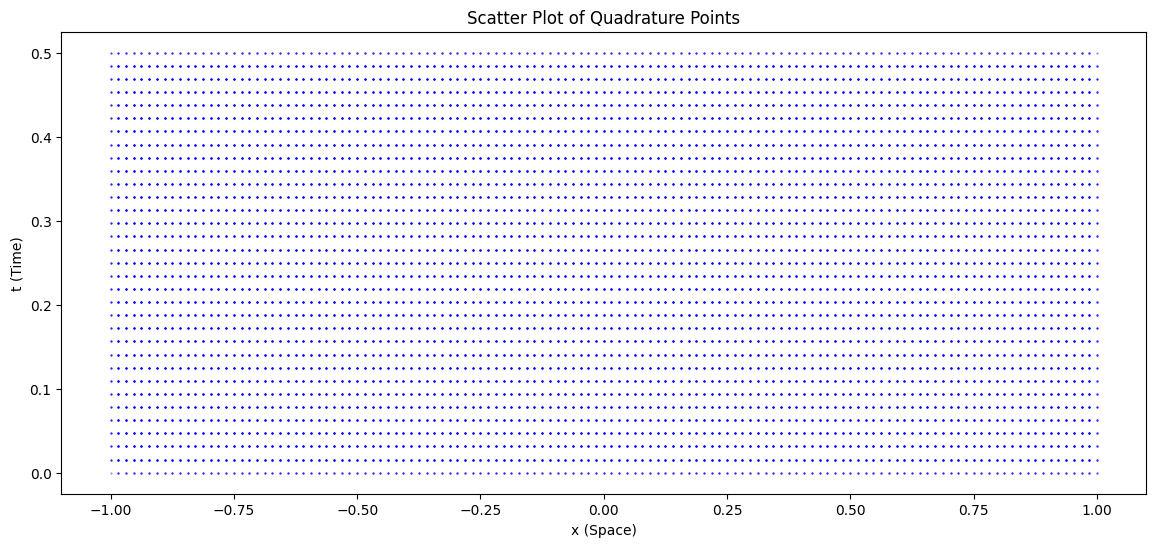

In [15]:
import matplotlib.pyplot as plt

def plot_quadrature_points(pwp):
    """
    Plot a scatter plot of all quadrature points from the PiecewiseLinearPolynomials class.

    Args:
        pwp: An instance of PiecewiseLinearPolynomials.
    """
    # Extract quadrature points
    quad_points = pwp.quad_points  # Shape: (N_quad, 2)

    # Extract t and x coordinates
    t_values = quad_points[:, 0]
    x_values = quad_points[:, 1]

    # Create scatter plot
    plt.figure(figsize=(14, 6))
    plt.scatter(x_values, t_values, s=1, c='blue', marker='.', alpha=0.5)
    plt.xlabel('x (Space)')
    plt.ylabel('t (Time)')
    plt.title('Scatter Plot of Quadrature Points')
    plt.show()
plot_quadrature_points(optProb.pwp)

In [24]:
import matplotlib.pyplot as plt
import jax.numpy as jnp
from jax import vmap

def plot_kh1(pwp, M_factor=10):
    """
    Plot the piecewise linear polynomial k_h over the domain [t_min, t_max] x [x_min, x_max]
    on a triangular mesh, using JAX for efficiency.

    Args:
        pwp: PiecewiseLinearPolynomials instance with N_t, N_x, t_min, t_max, x_min, x_max, and coeffs.
        M_factor: Factor to refine the plotting grid (default: 10).
    """
    # Retrieve ranges and grid parameters from pwp
    t_min, t_max = pwp.t_min, pwp.t_max
    x_min, x_max = pwp.x_min, pwp.x_max
    N_t, N_x = pwp.N_t, pwp.N_x
    tau = (t_max - t_min) / N_t  # Step size for t
    hx = (x_max - x_min) / N_x   # Step size for x

    # Create fine grid using JAX arrays
    M_t, M_x = N_t * M_factor, N_x * M_factor
    t_grid = jnp.linspace(t_min, t_max, M_t)
    x_grid = jnp.linspace(x_min, x_max, M_x)
    t, x = jnp.meshgrid(t_grid, x_grid, indexing='ij')  # Shapes: (M_t, M_x)

    # Flatten the grid for vectorized operations
    tx_points = jnp.stack([t.ravel(), x.ravel()], axis=1)  # Shape: (M_t * M_x, 2)

    # Function to find the element index for a single point
    def find_element(tx):
        t_val, x_val = tx
        # Find the rectangle containing the point
        i = jnp.floor((t_val - t_min) / tau).astype(int)
        j = jnp.floor((x_val - x_min) / hx).astype(int)
        i = jnp.clip(i, 0, N_t - 1)
        j = jnp.clip(j, 0, N_x - 1)

        # Get vertices of the two triangles in this rectangle
        A = jnp.array([t_min + i * tau, x_min + j * hx])
        B = jnp.array([t_min + (i + 1) * tau, x_min + j * hx])
        C = jnp.array([t_min + i * tau, x_min + (j + 1) * hx])
        D = jnp.array([t_min + (i + 1) * tau, x_min + (j + 1) * hx])

        # Check which triangle contains the point
        in_triangle_1 = point_in_triangle(tx, A, B, C)
        in_triangle_2 = point_in_triangle(tx, B, D, C)
        global_idx = jnp.where(
            in_triangle_1,
            2 * (i * N_x + j),        # First triangle
            jnp.where(
                in_triangle_2,
                2 * (i * N_x + j) + 1,  # Second triangle
                -1                      # Not in any triangle
            )
        )
        return global_idx

    # Vectorize the find_element function over all points
    element_indices = vmap(find_element)(tx_points)  # Shape: (M_t * M_x,)

    # Evaluate k_h at all points using their corresponding element indices
    kh_values = pwp.evaluate(tx_points, element_indices)  # Shape: (M_t * M_x,)
    kh_values = kh_values.reshape(M_t, M_x)  # Reshape to (M_t, M_x)

    # Plot using pcolormesh
    height = int((t_max - t_min)*4)
    width = int((x_max - x_min)*4 + 1)
    plt.figure(figsize=(width, height))
    plt.pcolormesh(x_grid, t_grid, kh_values, shading='nearest', cmap='viridis')
    plt.colorbar(label='$k_h(t, x)$')
    plt.xlabel('x')
    plt.ylabel('t')
    plt.title('Piecewise Linear Polynomial $k_h$ on Triangular Mesh')
    plt.show()

def point_in_triangle(P, A, B, C):
    """
    Check if point P is inside triangle ABC using barycentric coordinates.

    Args:
        P: Point to check, shape (2,).
        A, B, C: Triangle vertices, each shape (2,).

    Returns:
        Boolean: True if P is inside the triangle, False otherwise.
    """
    def sign(p1, p2, p3):
        return (p2[0] - p1[0]) * (p3[1] - p1[1]) - (p2[1] - p1[1]) * (p3[0] - p1[0])

    d1 = sign(P, A, B)
    d2 = sign(P, B, C)
    d3 = sign(P, C, A)
    has_neg = (d1 < 0) | (d2 < 0) | (d3 < 0)
    has_pos = (d1 > 0) | (d2 > 0) | (d3 > 0)
    return ~(has_neg & has_pos)  # True if all signs are the same or zero

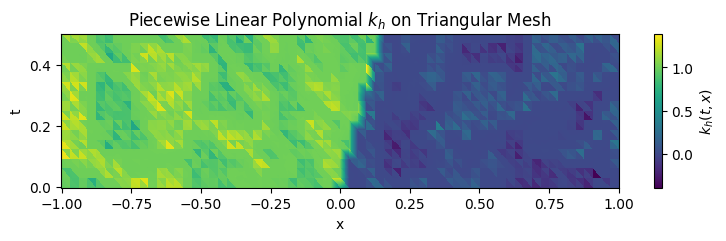

In [27]:
optProb.sigma = 0.1
optProb.pwp.coeffs, _ = optProb.maximize_kh_vec(optProb.params, optProb.key)
plot_kh1(optProb.pwp,  M_factor=10)

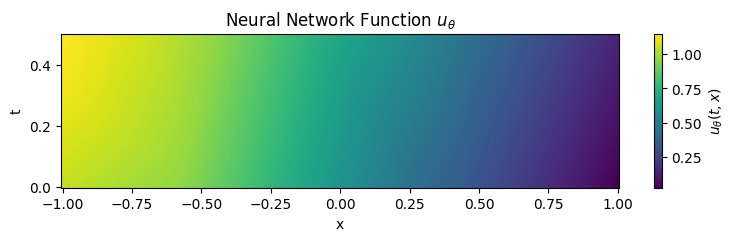

In [37]:
plot_u_theta(optProb.model, optProb.params, M_t=100, M_x=200, t_min=0.0, t_max=0.5, x_min=-1.0, x_max=1.0)  # Plot initial model state


In [17]:
jnp.linalg.norm(pwp.quad_weights - pwp1.quad_weights)

Array(0., dtype=float32)

In [12]:
jnp.sum(pwp.quad_weights)

Array(1., dtype=float32)

In [32]:
jnp.sum((pwp1.quad_weights * jnp.ones(2400)))

Array(1., dtype=float32)

In [38]:
optProb.model.apply(optProb.params, optProb.pwp.quad_points).shape

(24576,)

In [47]:
import jax.numpy as jnp

# Define the vectors
vector1 = jnp.ones((20,1))  # Shape (20,1)
vector2 = jnp.ones(20)      # Shape (20,)

# Flatten vector1 to shape (20,)
vector1_flat = vector1.flatten()

# Compute the dot product
dot_product = jnp.dot(vector1_flat, vector2)

print(dot_product)  # Outputs 20.0

20.0


In [48]:
quad_points = optProb.pwp.quad_points  # Shape: (Nt*Nq, 2)
      
u_quad = optProb.model.apply({'params': optProb.params}, quad_points)

In [49]:
grad_u = vmap(grad(lambda tx: optProb.model.apply({'params': optProb.params}, tx).squeeze()))(quad_points)
u_t, u_x = grad_u[:, 0], grad_u[:, 1]

hessian_u = jax.hessian(lambda tx: optProb.model.apply({'params': optProb.params}, tx).squeeze())
hessians = vmap(hessian_u)(quad_points)  # Shape: (Nt*Nq, 2, 2)
u_xx = hessians[:, 1, 1]

In [50]:
res_visc(u_quad, u_t, u_x, u_xx, optProb.nu).shape

(24576,)

In [51]:
residual = optProb.res_visc(u_quad, u_t, u_x, u_xx, optProb.nu)

In [5]:
jnp.stack([optProb.pwp.t_min * jnp.ones_like(optProb.x_bc), optProb.x_bc], axis=1).shape

(400, 2)

In [9]:
quad_points = optProb.pwp.quad_points
def u0(x):
    # return 2*smooth_sign(x) - 1
    return -0.5*(jnp.sign(x) - 1)
    # return -jnp.sin(jnp.pi*x)
def u_exact(tx):
    t, x = tx[0], tx[1]
    return u0(x-0.5*t)

vmap(u_exact)(quad_points).shape

(24576,)

In [7]:
jnp.ones((24576,)) * jnp.ones((24576,))

Array([1., 1., 1., ..., 1., 1., 1.], dtype=float32)

In [19]:
grad_u = vmap(grad(lambda tx: optProb.model.apply({'params': optProb.params}, tx)))(quad_points)
u_x = grad_u[:,1]
u = optProb.model.apply({'params': optProb.params}, quad_points)

In [22]:
grad_u2 = vmap(grad(lambda tx: 0.5*optProb.model.apply({'params': optProb.params}, tx)**2))(quad_points)
u2_x = grad_u2[:,1]

In [10]:
x = np.linspace(-1,1,100)

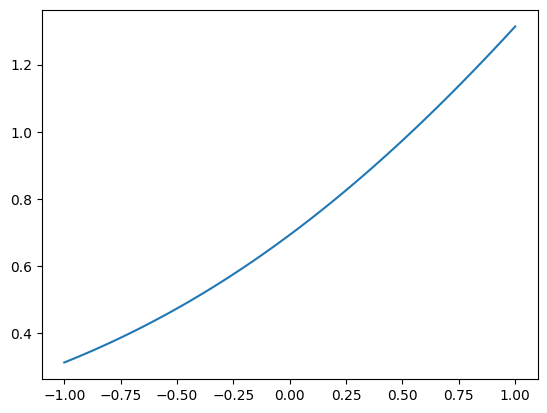

In [11]:
def softplus(x):                               # Softplus
    return np.log(1 + np.exp(x))

plt.plot(x, softplus(x))

In [13]:
softplus = jax.nn.softplus

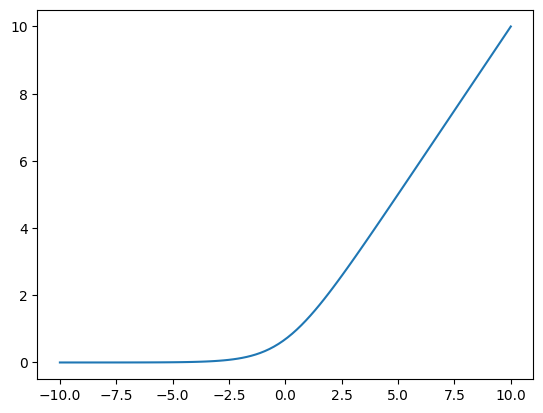

In [15]:
x = np.linspace(-10,10,100)
plt.plot(x, softplus(x))

In [7]:
import jax.numpy as jnp
import flax.linen as nn

class MLP(nn.Module):
    hidden_dims: list = (64, 64)
    activation: callable = nn.relu
    lb: jnp.ndarray = None
    ub: jnp.ndarray = None

    def setup(self):
        self.a = self.param('a', lambda key: jnp.sqrt(0.01))
        # Assign unique names to each Dense layer in the list
        self.layers = [nn.Dense(dim, name=f'dense_{i}') for i, dim in enumerate(self.hidden_dims)]
        self.output_layer = nn.Dense(1, name='output')

    def __call__(self, x):
        if self.lb is not None and self.ub is not None:
            x = 2.0 * (x - self.lb) / (self.ub - self.lb) - 1.0
        else:
            raise ValueError("Bounds lb and ub must be provided for normalization.")
        for layer in self.layers:
            z = layer(x)
            x = self.activation(10.0 * self.a * z)
        x = self.output_layer(x)
        return x.squeeze()

In [8]:
model = MLP(hidden_dims=[20]*8, activation=nn.tanh, lb=jnp.array([0.0, -1.0]), ub=jnp.array([1.0, 1.0]))
key = jax.random.PRNGKey(0)
params = model.init(key, jnp.ones((1, 2)))['params']